In [1]:
import sys
import os
from pathlib import Path

# 1. Google Colab環境であり、まだリポジトリをクローンしていない場合の処理
if "google.colab" in sys.modules and not Path("src").exists():
    repo_name = "Mohs-hardness-prediction"
    if not Path(repo_name).exists():
        print("GitHubからリポジトリをクローン中...")
        !git clone https://github.com/sho441/Mohs-hardness-prediction.git

    # 作業ディレクトリをリポジトリ内に移動
    os.chdir(repo_name)
    print(f"作業ディレクトリを移動しました: {os.getcwd()}")

# 2. プロジェクトルートをパスに追加
current_dir = Path().resolve()
if current_dir.name == "notebooks":
    project_root = current_dir.parent
else:
    project_root = current_dir

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

# 3. グラフスタイル設定
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial"]

# 4. 動作確認用インポート
from src.config import TRAIN_PATH, TEST_PATH
from src.features import preprocess_data

print(f"プロジェクトルート: {project_root}")
print("環境セットアップ＆インポート成功！")

作業ディレクトリを移動しました: /content/Mohs-hardness-prediction
プロジェクトルート: /content/Mohs-hardness-prediction
環境セットアップ＆インポート成功！


In [2]:
# データのロード
train_df = pd.read_csv(
    TRAIN_PATH
)
test_df = pd.read_csv(
    TEST_PATH
)

print(
    "訓練データ形状: "
    f"{train_df.shape}"
)
print(
    "テストデータ形状: "
    f"{test_df.shape}"
)

# 先頭行の確認
display(train_df.head())

# データ型や欠損値の確認
train_df.info()

訓練データ形状: (10407, 13)
テストデータ形状: (6939, 12)


,id,allelectrons_Total,density_Total,allelectrons_Average,val_e_Average,atomicweight_Average,ionenergy_Average,el_neg_chi_Average,R_vdw_element_Average,R_cov_element_Average,zaratio_Average,density_Average,Hardness
0,0,100.0,0.841611,10.0,4.8,20.612526,11.08810,2.766,1.732,0.860,0.496070,0.91457,6.0
1,1,100.0,7.558488,10.0,4.8,20.298893,12.04083,2.755,1.631,0.910,0.492719,0.71760,6.5
2,2,76.0,8.885992,15.6,5.6,33.739258,12.08630,2.828,1.788,0.864,0.481478,1.50633,2.5
3,3,100.0,8.795296,10.0,4.8,20.213349,10.94850,2.648,1.626,0.936,0.489272,0.78937,6.0
4,4,116.0,9.577996,11.6,4.8,24.988133,11.82448,2.766,1.682,0.896,0.492736,1.86481,6.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10407 entries, 0 to 10406
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id                     10407 non-null  int64  
 1   allelectrons_Total     10407 non-null  float64
 2   density_Total          10407 non-null  float64
 3   allelectrons_Average   10407 non-null  float64
 4   val_e_Average          10407 non-null  float64
 5   atomicweight_Average   10407 non-null  float64
 6   ionenergy_Average      10407 non-null  float64
 7   el_neg_chi_Average     10407 non-null  float64
 8   R_vdw_element_Average  10407 non-null  float64
 9   R_cov_element_Average  10407 non-null  float64
 10  zaratio_Average        10407 non-null  float64
 11  density_Average        10407 non-null  float64
 12  Hardness               10407 non-null  float64
dtypes: float64(12), int64(1)
memory usage: 1.0 MB


In [3]:
target_col = "target"

if target_col in train_df.columns:
    plt.figure(figsize=(8, 4))
    sns.histplot(
        train_df[target_col],
        kde=True,
        bins=30,
        color="teal",
    )
    plt.title(
        "Target Distribution"
        " (Mohs Hardness)"
    )
    plt.xlabel("Mohs Hardness")
    plt.ylabel("Count")
    plt.show()

    # 統計量の確認
    display(
        train_df[target_col]
        .describe()
    )
else:
    print(
        f"ターゲット '{target_col}' "
        "が見つかりません。"
    )

ターゲット 'target' が見つかりません。


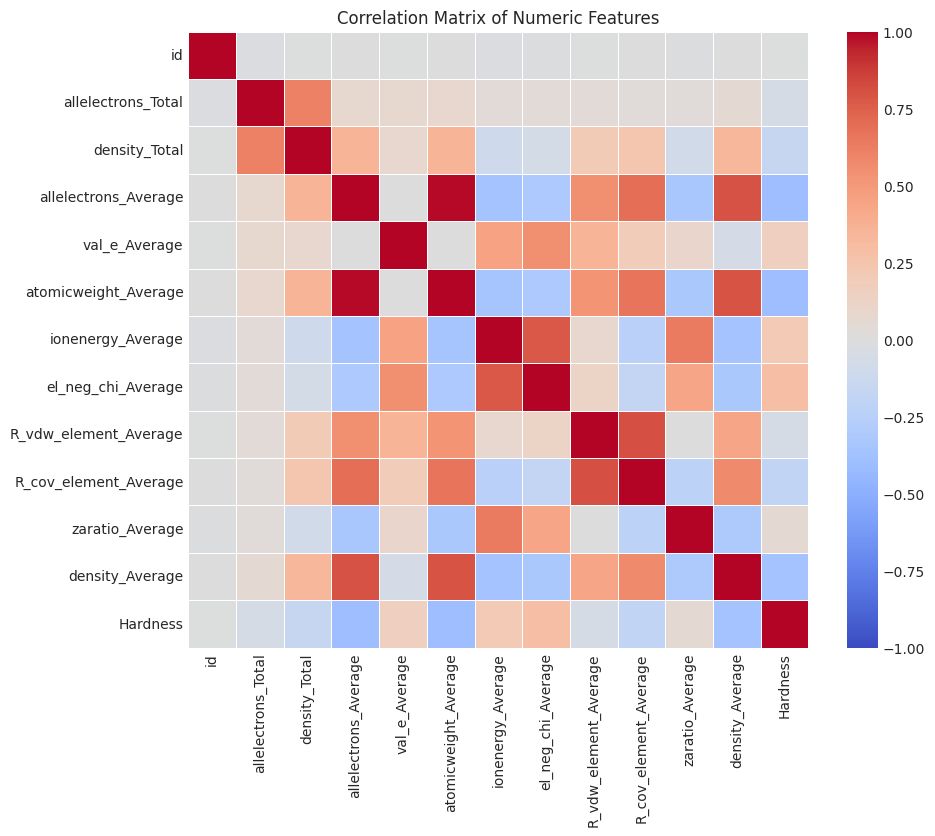

In [4]:
plt.figure(figsize=(10, 8))
numeric_df = (
    train_df.select_dtypes(
        include=[np.number]
    )
)
correlation = (
    numeric_df.corr()
)

sns.heatmap(
    correlation,
    annot=False,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
)
plt.title(
    "Correlation Matrix "
    "of Numeric Features"
)
plt.show()

In [5]:
# 特徴量とターゲットの分離
if target_col in train_df.columns:
    y_sample = (
        train_df[target_col]
    )
    X_sample = (
        train_df.drop(
            columns=[target_col]
        )
    )
else:
    X_sample = train_df.copy()

# 前処理パイプラインのテスト実行
X_processed, test_processed = (
    preprocess_data(
        X_sample, test_df
    )
)

print(
    "前処理後 訓練データ形状: "
    f"{X_processed.shape}"
)
print(
    "前処理後 テストデータ形状: "
    f"{test_processed.shape}"
)
print(
    "欠損値数（訓練）: "
    f"{X_processed.isnull().sum().sum()}"
)
print(
    "欠損値数（テスト）: "
    f"{test_processed.isnull().sum().sum()}"
)

前処理後 訓練データ形状: (10407, 13)
前処理後 テストデータ形状: (6939, 12)
欠損値数（訓練）: 0
欠損値数（テスト）: 0
